# Experimento: predicción de supervivencia en el Titanic

## 1. Objetivo

El experimento construye un modelo de clasificación binaria que indica si un pasajero del Titanic **sobreviviría** (`Survived = 1`) o **no sobreviviría** (`Survived = 0`) a partir de sus características (clase, sexo, edad, familia a bordo, tarifa y puerto de embarque).

Se comparan dos modelos, **Regresión Logística** y **Random Forest**, y se selecciona el más conveniente. El preprocesamiento y el modelo se integran en un `Pipeline` de Scikit-learn, que posteriormente se serializa para ser reutilizado por la interfaz Streamlit y la API FastAPI.

## 2. Importación de librerías

Se importan las librerías para manipulación de datos, visualización, preprocesamiento, modelado, evaluación y serialización.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 3. Carga de datos

Se localiza la raíz del proyecto (el notebook puede ejecutarse desde `notebooks/` o desde la raíz) y se carga `data/titanic.csv`.

In [2]:
# Raíz del proyecto: carpeta que contiene data/
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RUTA_DATOS = RAIZ / "data" / "titanic.csv"

datos = pd.read_csv(RUTA_DATOS)
datos.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 4. Exploración de datos

Se revisan las dimensiones, los tipos de datos, los valores faltantes y la distribución de la variable objetivo `Survived`.

In [3]:
print(f"Dimensiones: {datos.shape}")
datos.info()

Dimensiones: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [4]:
# Valores faltantes por columna
faltantes = datos.isna().sum()
faltantes[faltantes > 0].to_frame("faltantes").assign(
    porcentaje=lambda t: (t["faltantes"] / len(datos) * 100).round(1)
)

,faltantes,porcentaje
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


In [5]:
# Distribución de la variable objetivo
datos["Survived"].value_counts().to_frame("pasajeros").assign(
    porcentaje=lambda t: (t["pasajeros"] / len(datos) * 100).round(1)
)

,pasajeros,porcentaje
Survived,,
0,549,61.6
1,342,38.4


Se observa que el conjunto contiene 891 pasajeros, de los cuales aproximadamente el **38 %** sobrevivió. Las clases están moderadamente desbalanceadas, por lo que además de Accuracy se utilizarán F1 y ROC-AUC.

Existen valores faltantes en `Age` (~20 %), `Cabin` (~77 %) y `Embarked` (2 registros).

## 5. Análisis visual

Se analiza la tasa de supervivencia según el sexo y la clase del pasajero, y la distribución de la edad según la supervivencia.

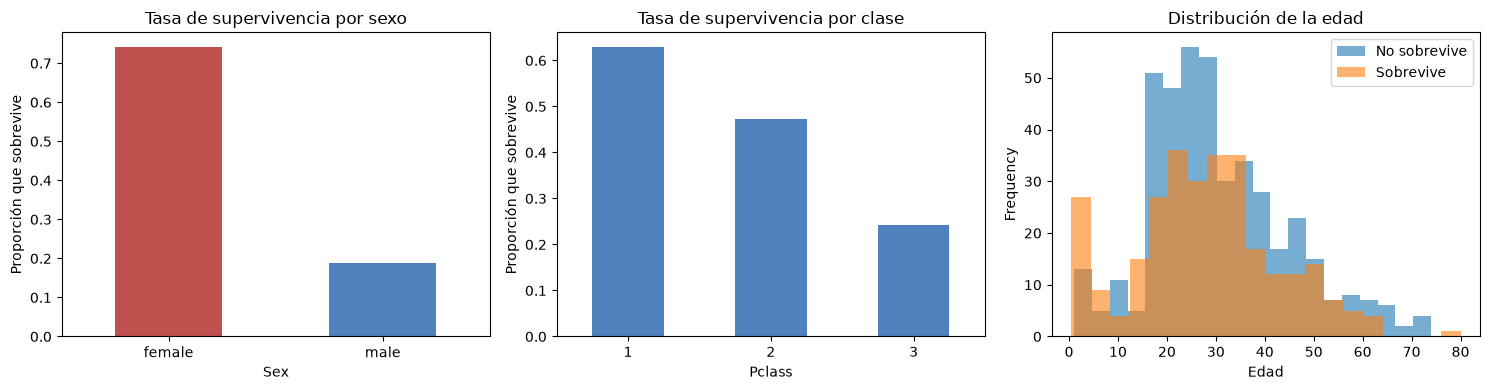

In [6]:
figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

datos.groupby("Sex")["Survived"].mean().plot.bar(ax=ejes[0], color=["#c0504d", "#4f81bd"])
ejes[0].set_title("Tasa de supervivencia por sexo")
ejes[0].set_ylabel("Proporción que sobrevive")
ejes[0].tick_params(axis="x", rotation=0)

datos.groupby("Pclass")["Survived"].mean().plot.bar(ax=ejes[1], color="#4f81bd")
ejes[1].set_title("Tasa de supervivencia por clase")
ejes[1].set_ylabel("Proporción que sobrevive")
ejes[1].tick_params(axis="x", rotation=0)

for valor, etiqueta in [(0, "No sobrevive"), (1, "Sobrevive")]:
    datos.loc[datos["Survived"] == valor, "Age"].plot.hist(
        ax=ejes[2], bins=20, alpha=0.6, label=etiqueta
    )
ejes[2].set_title("Distribución de la edad")
ejes[2].set_xlabel("Edad")
ejes[2].legend()

plt.tight_layout()
plt.show()

Los gráficos muestran los patrones conocidos del naufragio:

- Las **mujeres** sobrevivieron en una proporción muy superior a los hombres.
- La **primera clase** tuvo una tasa de supervivencia notablemente mayor que la tercera.
- Los **niños** pequeños presentan mayor proporción de supervivencia.

Estas variables serán, previsiblemente, las más relevantes para el modelo.

## 6. Selección de variables

Se descartan las siguientes columnas:

| Columna | Motivo |
|---|---|
| `PassengerId` | Identificador sin valor predictivo. |
| `Name` | Texto libre (único por pasajero). |
| `Ticket` | Código alfanumérico sin estructura homogénea. |
| `Cabin` | 77 % de valores faltantes. |

In [7]:
COLUMNAS_NUMERICAS = ["Age", "SibSp", "Parch", "Fare"]
COLUMNAS_CATEGORICAS = ["Pclass", "Sex", "Embarked"]
COLUMNAS = COLUMNAS_NUMERICAS + COLUMNAS_CATEGORICAS

datos_modelo = datos.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
datos_modelo.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 7. Variables predictoras y objetivo

Se separan las variables predictoras ($X$) de la variable objetivo ($y$ = `Survived`). `Pclass` se trata como categórica, ya que representa niveles de clase y no una magnitud continua.

In [8]:
X = datos_modelo[COLUMNAS]
y = datos_modelo["Survived"]
print(f"X: {X.shape} | y: {y.shape}")

X: (891, 7) | y: (891,)


## 8. División entrenamiento / prueba

Se reserva el 20 % de los datos para la evaluación final, con división estratificada para conservar la proporción de sobrevivientes.

In [9]:
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Entrenamiento: {len(X_entrenamiento)} | Prueba: {len(X_prueba)}")

Entrenamiento: 712 | Prueba: 179


## 9. Preprocesamiento

Se define un `ColumnTransformer` que aplica:

- **Numéricas:** imputación por mediana (resuelve los faltantes de `Age`) y estandarización con `StandardScaler` (necesaria para la Regresión Logística).
- **Categóricas:** imputación por el valor más frecuente (resuelve `Embarked`) y codificación `OneHotEncoder`.

Al formar parte del Pipeline, las mismas transformaciones se aplicarán automáticamente en la inferencia.

In [10]:
def crear_preprocesador():
    numericas = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
    ])
    categoricas = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numericas", numericas, COLUMNAS_NUMERICAS),
        ("categoricas", categoricas, COLUMNAS_CATEGORICAS),
    ])

## 10. Definición de los modelos

Se construye un Pipeline por modelo, compartiendo el mismo preprocesamiento:

- **Regresión Logística:** modelo lineal, simple e interpretable.
- **Random Forest:** conjunto de árboles capaz de capturar relaciones no lineales e interacciones (`max_depth=6` limita el sobreajuste).

In [11]:
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
}

pipelines = {
    nombre: Pipeline([("preprocesador", crear_preprocesador()), ("clasificador", modelo)])
    for nombre, modelo in modelos.items()
}

## 11. Comparación mediante validación cruzada

Se evalúan ambos Pipelines con validación cruzada estratificada de 5 particiones **sobre el conjunto de entrenamiento**, de modo que el conjunto de prueba se reserve exclusivamente para la evaluación final.

In [12]:
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas_cv = ["accuracy", "f1", "roc_auc"]

filas = []
for nombre, pipeline in pipelines.items():
    resultados = cross_validate(pipeline, X_entrenamiento, y_entrenamiento, cv=validacion, scoring=metricas_cv)
    fila = {"modelo": nombre}
    for metrica in metricas_cv:
        fila[f"{metrica}_media"] = resultados[f"test_{metrica}"].mean()
        fila[f"{metrica}_desv"] = resultados[f"test_{metrica}"].std()
    filas.append(fila)

comparacion = pd.DataFrame(filas).set_index("modelo").round(4)
comparacion

,accuracy_media,accuracy_desv,f1_media,f1_desv,roc_auc_media,roc_auc_desv
modelo,,,,,,
Regresión Logística,0.8020,0.0142,0.7301,0.0217,0.8532,0.0218
Random Forest,0.8146,0.0322,0.7339,0.0453,0.8692,0.0236


## 12. Selección del modelo

Se aplica el criterio definido en el proyecto: **Random Forest se selecciona únicamente si mejora el F1 medio de la Regresión Logística en al menos 0.02**. En caso contrario, se prefiere la Regresión Logística por ser más simple, rápida e interpretable.

Se utiliza F1 como métrica principal porque equilibra Precision y Recall en un problema con clases desbalanceadas.

In [13]:
UMBRAL_MEJORA = 0.02
diferencias = (comparacion.loc["Random Forest"] - comparacion.loc["Regresión Logística"])[
    ["accuracy_media", "f1_media", "roc_auc_media"]
]
print("Diferencia (Random Forest - Regresión Logística):")
print(diferencias.round(4).to_string())

nombre_modelo = "Random Forest" if diferencias["f1_media"] >= UMBRAL_MEJORA else "Regresión Logística"
print(f"\nModelo seleccionado: {nombre_modelo}")

Diferencia (Random Forest - Regresión Logística):
accuracy_media    0.0126
f1_media          0.0038
roc_auc_media     0.0160

Modelo seleccionado: Regresión Logística


Random Forest obtiene valores medios ligeramente superiores, pero la mejora en F1 es inferior a un punto porcentual y las diferencias en Accuracy y ROC-AUC son menores que la variabilidad entre particiones (desviación estándar). Es decir, ambos modelos rinden de forma **prácticamente equivalente**.

Ante un desempeño equivalente, se selecciona la **Regresión Logística**: es más simple, genera un archivo serializado más liviano, responde más rápido en la API y sus coeficientes permiten explicar directamente el efecto de cada variable.

## 13. Entrenamiento y evaluación en prueba

Se entrena el modelo seleccionado con el conjunto de entrenamiento y se evalúa sobre el conjunto de prueba, que no ha sido utilizado en ninguna etapa anterior.

In [14]:
modelo = pipelines[nombre_modelo]
modelo.fit(X_entrenamiento, y_entrenamiento)

y_prediccion = modelo.predict(X_prueba)
y_probabilidad = modelo.predict_proba(X_prueba)[:, 1]

metricas_prueba = {
    "accuracy": accuracy_score(y_prueba, y_prediccion),
    "precision": precision_score(y_prueba, y_prediccion),
    "recall": recall_score(y_prueba, y_prediccion),
    "f1": f1_score(y_prueba, y_prediccion),
    "roc_auc": roc_auc_score(y_prueba, y_probabilidad),
}
metricas_prueba = {clave: round(float(valor), 4) for clave, valor in metricas_prueba.items()}
pd.Series(metricas_prueba, name=nombre_modelo).to_frame()

,Regresión Logística
accuracy,0.8045
precision,0.7931
recall,0.6667
f1,0.7244
roc_auc,0.8427


              precision    recall  f1-score   support

No sobrevive       0.81      0.89      0.85       110
   Sobrevive       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



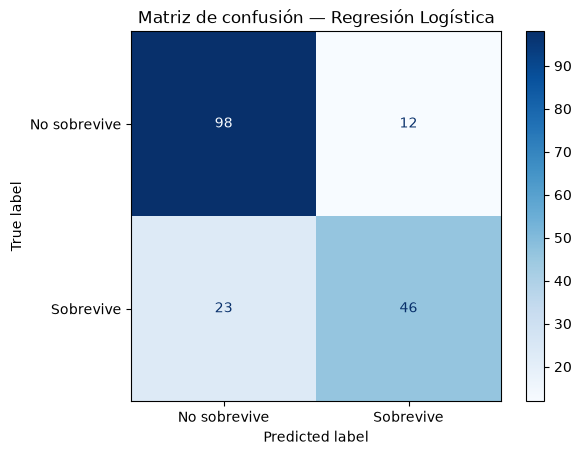

In [15]:
print(classification_report(y_prueba, y_prediccion, target_names=["No sobrevive", "Sobrevive"]))

ConfusionMatrixDisplay.from_predictions(
    y_prueba, y_prediccion, display_labels=["No sobrevive", "Sobrevive"], cmap="Blues"
)
plt.title(f"Matriz de confusión — {nombre_modelo}")
plt.show()

Las métricas en prueba son coherentes con las obtenidas en validación cruzada, lo que indica que el modelo **no presenta sobreajuste**:

- **Accuracy:** proporción total de pasajeros clasificados correctamente.
- **Precision:** de los pasajeros que el modelo predice como sobrevivientes, qué proporción realmente sobrevivió.
- **Recall:** de los pasajeros que realmente sobrevivieron, qué proporción detecta el modelo.
- **F1:** media armónica entre Precision y Recall.
- **ROC-AUC:** capacidad del modelo para ordenar a los pasajeros según su probabilidad de supervivencia (1 = perfecta, 0.5 = azar).

La matriz de confusión muestra que el error más frecuente corresponde a sobrevivientes clasificados como no sobrevivientes (falsos negativos), por eso el Recall es menor que la Precision.

## 14. Interpretación del modelo

Se muestran los **coeficientes** (Regresión Logística) o la **importancia de variables** (Random Forest) del modelo seleccionado, utilizando los nombres de las variables tras el preprocesamiento.

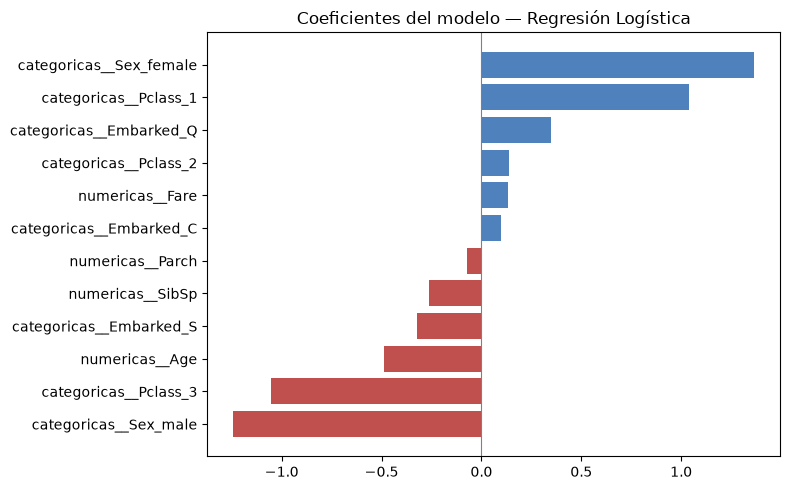

,Variable,Coeficiente
11,categoricas__Sex_female,1.364
10,categoricas__Pclass_1,1.039
9,categoricas__Embarked_Q,0.348
8,categoricas__Pclass_2,0.138
7,numericas__Fare,0.134
6,categoricas__Embarked_C,0.096
5,numericas__Parch,-0.071
4,numericas__SibSp,-0.261
3,categoricas__Embarked_S,-0.322
2,numericas__Age,-0.489


In [16]:
clasificador = modelo.named_steps["clasificador"]
nombres_variables = modelo.named_steps["preprocesador"].get_feature_names_out()

if hasattr(clasificador, "coef_"):
    valores, etiqueta = clasificador.coef_[0], "Coeficiente"
else:
    valores, etiqueta = clasificador.feature_importances_, "Importancia"

interpretacion = (
    pd.DataFrame({"Variable": nombres_variables, etiqueta: valores})
    .sort_values(etiqueta)
    .reset_index(drop=True)
)

plt.figure(figsize=(8, 5))
colores = ["#c0504d" if v < 0 else "#4f81bd" for v in interpretacion[etiqueta]]
plt.barh(interpretacion["Variable"], interpretacion[etiqueta], color=colores)
plt.axvline(0, color="grey", linewidth=0.8)
plt.title(f"{etiqueta}s del modelo — {nombre_modelo}")
plt.tight_layout()
plt.show()

interpretacion.sort_values(etiqueta, ascending=False).round(3)

En la Regresión Logística, un coeficiente **positivo** aumenta la probabilidad de sobrevivir y uno **negativo** la disminuye (las variables numéricas están estandarizadas, por lo que sus coeficientes son comparables entre sí).

Se confirma lo observado en el análisis visual:

- Ser **mujer** (`Sex_female`) es el factor que más aumenta la probabilidad de supervivencia; ser hombre, el que más la reduce.
- Viajar en **primera clase** aumenta la probabilidad; viajar en **tercera clase** la reduce.
- Una mayor **edad** y un mayor número de **hermanos/cónyuges** a bordo (`SibSp`) reducen la probabilidad de sobrevivir.

## 15. Serialización del modelo

Una vez validado, el Pipeline seleccionado se **reentrena con todos los datos** (entrenamiento + prueba) para aprovechar la totalidad de la información disponible en producción. Las métricas registradas corresponden a la evaluación anterior.

Se guarda con Joblib un diccionario con el modelo, las columnas esperadas, el nombre del modelo y una versión basada en la fecha (UTC). Las métricas se guardan en `metricas.json`.

In [17]:
modelo_final = Pipeline([
    ("preprocesador", crear_preprocesador()),
    ("clasificador", modelos[nombre_modelo]),
])
modelo_final.fit(X, y)

version = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
CARPETA_MODELOS = RAIZ / "modelos"
CARPETA_MODELOS.mkdir(exist_ok=True)

paquete = {
    "modelo": modelo_final,
    "columnas": COLUMNAS,
    "nombre_modelo": nombre_modelo,
    "version": version,
}
joblib.dump(paquete, CARPETA_MODELOS / "modelo_titanic.joblib")

metricas = {
    "modelo": nombre_modelo,
    "version": version,
    "validacion_cruzada": comparacion.reset_index().to_dict(orient="records"),
    "prueba": metricas_prueba,
    "registros_entrenamiento": int(len(X_entrenamiento)),
    "registros_prueba": int(len(X_prueba)),
}
(CARPETA_MODELOS / "metricas.json").write_text(
    json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(f"Modelo guardado: {CARPETA_MODELOS / 'modelo_titanic.joblib'} | versión: {version}")

Modelo guardado: D:\Users\hp\Documents\My\Cursos\POSTGRADO\CIENCIA DE DATOS\Modulo_5\Ejercicios\Practica_1\modelos\modelo_titanic.joblib | versión: 20261122T003826Z


## 16. Prueba del modelo serializado

Se carga el archivo guardado y se realiza una predicción sobre un pasajero de ejemplo, simulando el uso que harán Streamlit y FastAPI.

In [18]:
paquete_cargado = joblib.load(CARPETA_MODELOS / "modelo_titanic.joblib")

pasajero = pd.DataFrame([{
    "Pclass": 3, "Sex": "male", "Age": 25, "SibSp": 0,
    "Parch": 0, "Fare": 7.25, "Embarked": "S",
}])[paquete_cargado["columnas"]]

prediccion = paquete_cargado["modelo"].predict(pasajero)[0]
probabilidad = paquete_cargado["modelo"].predict_proba(pasajero)[0, 1]

print(f"Modelo: {paquete_cargado['nombre_modelo']} (versión {paquete_cargado['version']})")
print(f"Predicción: {'Sobrevive' if prediccion == 1 else 'No sobrevive'}")
print(f"Probabilidad de supervivencia: {probabilidad:.1%}")

Modelo: Regresión Logística (versión 20261122T003826Z)
Predicción: No sobrevive
Probabilidad de supervivencia: 10.5%


## 17. Conclusiones

- Se construyó un Pipeline completo (imputación, escalado, codificación y clasificador) que evita inconsistencias entre entrenamiento e inferencia.
- La Regresión Logística y el Random Forest obtuvieron un desempeño prácticamente equivalente en validación cruzada (Accuracy ≈ 0.80–0.81, ROC-AUC ≈ 0.85–0.87).
- Se seleccionó la **Regresión Logística** por su simplicidad, interpretabilidad y menor costo de inferencia, con un desempeño en prueba de Accuracy ≈ 0.80 y ROC-AUC ≈ 0.84.
- El sexo y la clase del pasajero son los factores más determinantes en la supervivencia.
- El modelo serializado (`modelos/modelo_titanic.joblib`) queda disponible para el script de entrenamiento, la interfaz Streamlit y la API FastAPI.